# Clustering earthquake epicentres

**Goal:** apply K-means++, DBSCAN, HDBSCAN, GMM and Spectral to earthquake epicentres, choose
their parameters from evidence, and explain where each method succeeds or fails. This notebook is
Stage 3 and 4 of `../AGENTS.md`.

**Input:** `load_earthquakes()` with the decisions from `07_usgs_earthquakes_2023_eda.ipynb`, section 12: volcanic
eruptions dropped, magnitude 4.5 and above for all of 2023, epicentre only (no depth, magnitude or time).

**Terms**

| Term | Meaning |
|---|---|
| earthquake | One row of the catalogue, clustered by its epicentre (latitude, longitude) |
| great-circle distance | Distance along the Earth's surface (haversine formula), in km |
| unit vector | An epicentre as a point (x, y, z) on a sphere of radius 1. K-means only supports straight-line distance, and straight-line distance between unit vectors grows with great-circle distance |
| belt | A long, narrow line of earthquakes along a plate boundary (EDA section 3) |
| noise | Earthquakes that DBSCAN or HDBSCAN leave out of every cluster (label -1) |
| silhouette | For each clustered earthquake: how much closer it is to its own cluster than to the next one, from -1 to 1. Computed with great-circle distance on non-noise earthquakes |
| Davies-Bouldin | Average ratio of cluster spread to distance between cluster centres; lower is better. Computed on unit vectors |
| inertia | K-means objective: total squared distance from each point to its cluster centre |
| ARI | Adjusted Rand index: agreement between two labellings, 1 = identical, about 0 = chance |
| shuffled null | Latitudes and longitudes shuffled independently (keeps each one's distribution, breaks the pairing) |
| uniform null | The same number of points uniform in the latitude and longitude bounding box of the data |
| DBCV | Density-Based Clustering Validation; measures density separation and compactness without relying on convex shapes. Computed on unit vectors |

As in Stage 0, the shuffled null is the baseline for K-means silhouette and the uniform null for
DBSCAN and HDBSCAN. Silhouette uses a sample of 5,000 earthquakes (seed 0).

**Seeds:** 0 for single runs and the uniform null; 0 to 2 for the three shuffled nulls; 0 to 9 for K
stability.

**Contents**
1. Data and features
2. K-means: choosing K
3. K-means: clusters on the map
4. DBSCAN: choosing eps and min_samples
5. HDBSCAN: parameter grid
6. What the density-based clusters contain
7. Gaussian Mixture Models (GMM)
8. Spectral clustering
9. Method comparison
10. Summary


In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.metrics import adjusted_rand_score

from sc4020 import methods, tuning
from sc4020.clusters import relabel_by_size
from sc4020.datasets import load_dataset
from sc4020.datasets.preprocess_dataset import (
    EARTH_RADIUS_KM,
    region_from_place,
    to_radians,
    to_unit_vectors,
)
from sc4020.metrics import (
    NOISE_LABEL,
    evaluate,
    nearest_neighbour_km,
)
from sc4020.paths import results_dir
from sc4020.tuning import shuffle_columns_independently, uniform_box_null

%matplotlib inline
pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 90)
SEED = 0
SILHOUETTE_SAMPLE = 5000
RESULTS = results_dir("earthquakes_2023")
FIGURES = RESULTS / "figures"
FIGURES.mkdir(exist_ok=True)

## 1. Data and features

In [2]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    events = load_dataset("earthquakes_2023").events
for warning in caught:
    print("warning:", warning.message)

degrees = events[["latitude", "longitude"]].to_numpy()


def features(deg):
    """Radians for haversine methods and unit vectors for K-means, from [latitude, longitude] degrees."""
    return to_radians(deg[:, 0], deg[:, 1]), to_unit_vectors(deg[:, 0], deg[:, 1])


R, U = features(degrees)
shuffled = [
    features(shuffle_columns_independently(degrees, np.random.default_rng(seed)))
    for seed in range(3)
]
uniform_degrees = uniform_box_null(degrees, np.random.default_rng(SEED))
R_uniform, U_uniform = features(uniform_degrees)
pd.DataFrame(
    {
        "earthquakes": [len(events)],
        "radians shape": [R.shape],
        "unit vector shape": [U.shape],
    }
)

,earthquakes,radians shape,unit vector shape
0,7643,"(7643, 2)","(7643, 3)"


## 2. K-means: choosing K

For K = 2 to 12, K-means++ with 10 starts on unit vectors:
- **Elbow:** inertia always falls as K grows; look for where the fall flattens.
- **Silhouette vs shuffled null:** only the gap above the null shows real structure.
- **Davies-Bouldin:** lower means tighter, better separated clusters.
- **Stability:** do 10 different seeds give the same clusters (mean pairwise ARI)? Are any clusters very small?

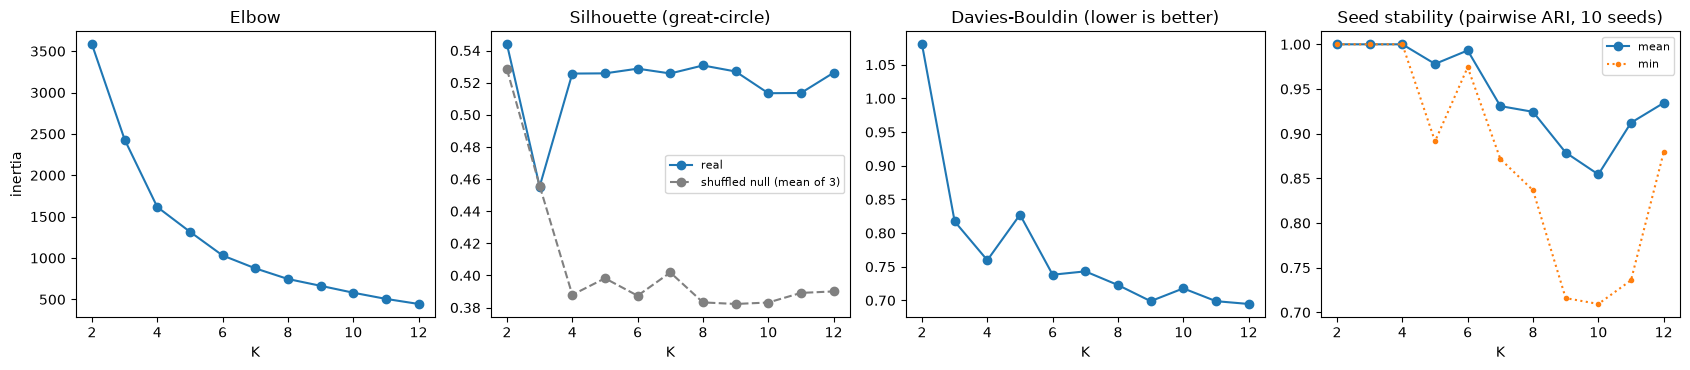

,K,inertia,silhouette,silhouette_null,silhouette_minus_null,davies_bouldin,smallest_cluster,largest_cluster,seed_stability_ari,seed_stability_min_ari
0,2,3582.843,0.544,0.528,1.559e-02,1.080,2109,5534,1.000,1.000
1,3,2432.297,0.455,0.456,-5.136e-04,0.817,1585,3907,1.000,1.000
2,4,1616.065,0.526,0.388,1.377e-01,0.760,999,3466,1.000,1.000
3,5,1317.259,0.526,0.398,1.276e-01,0.827,763,3336,0.978,0.891
4,6,1030.710,0.529,0.387,1.413e-01,0.738,490,2367,0.993,0.974
5,7,875.190,0.526,0.402,1.239e-01,0.743,336,2332,0.931,0.872
6,8,746.188,0.531,0.383,1.475e-01,0.723,264,2072,0.924,0.837
7,9,664.062,0.527,0.382,1.447e-01,0.699,240,1965,0.879,0.716
8,10,580.548,0.513,0.383,1.303e-01,0.718,308,1665,0.854,0.709
9,11,505.880,0.514,0.389,1.244e-01,0.699,207,1803,0.912,0.736


In [3]:
from sc4020.generate_figures import show_and_save_to

# K-Means on unit vectors, silhouette by great-circle distance; fake data shuffle the degree columns
k_choice = tuning.select_kmeans_k_by_null_gap(
    degrees,
    k_range=range(2, 13),
    to_features=lambda deg: features(deg)[1],
    to_silhouette_features=lambda deg: features(deg)[0],
    silhouette_metric="haversine",
    sample_size=SILHOUETTE_SAMPLE,
    random_state=SEED,
)
k_selection = pd.DataFrame(k_choice.tried).rename(
    columns={
        "n_clusters": "K",
        "null_silhouette": "silhouette_null",
        "null_gap": "silhouette_minus_null",
        "mean_seed_ari": "seed_stability_ari",
        "min_seed_ari": "seed_stability_min_ari",
    }
)
k_selection.to_csv(RESULTS / "kmeans_k_selection.csv", index=False)

fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
axes[0].plot(k_selection["K"], k_selection["inertia"], marker="o")
axes[0].set(title="Elbow", xlabel="K", ylabel="inertia")
axes[1].plot(k_selection["K"], k_selection["silhouette"], marker="o", label="real")
axes[1].plot(
    k_selection["K"],
    k_selection["silhouette_null"],
    marker="o",
    color="grey",
    linestyle="--",
    label="shuffled null (mean of 3)",
)
axes[1].set(title="Silhouette (great-circle)", xlabel="K")
axes[1].legend(fontsize=8)
axes[2].plot(k_selection["K"], k_selection["davies_bouldin"], marker="o")
axes[2].set(title="Davies-Bouldin (lower is better)", xlabel="K")
axes[3].plot(
    k_selection["K"], k_selection["seed_stability_ari"], marker="o", label="mean"
)
axes[3].plot(
    k_selection["K"],
    k_selection["seed_stability_min_ari"],
    marker=".",
    linestyle=":",
    label="min",
)
axes[3].set(title="Seed stability (pairwise ARI, 10 seeds)", xlabel="K")
axes[3].legend(fontsize=8)
plt.tight_layout()
show_and_save_to(fig, FIGURES / "kmeans_k_selection.png")
k_selection

**Observations**

- **No clear elbow.** Inertia falls by 32% from K=2 to 3 and 34% from 3 to 4, then 19% (K=5), 22% (K=6) and 11% to 15% per step after that.
- **K=2 and K=3 are no better than the null** (silhouette 0.544 vs 0.529, and 0.459 vs 0.458). These splits follow the distribution of latitude and longitude on their own, which the shuffled null keeps.
- **From K=4 the silhouette is flat:** 0.516 to 0.532 for K = 4 to 12, while the null stays at 0.378 to 0.399 (gap 0.126 to 0.149). Silhouette cannot choose among K of 4 or more; the belts are continuous, so each extra centre cuts them at a different place with a similar score.
- **Davies-Bouldin** has local minima at K=4 (0.760) and K=6 (0.738); K=5 is worse (0.827); the lowest is 0.695 at K=12.
- **Seed stability** is 1.000 for K = 2 to 4 and 0.993 at K=6 (worst pair 0.974). K=5 is 0.978 (worst 0.891), and K = 7 to 11 fall to 0.854 to 0.934 with worst pairs down to 0.709 (K=10).
- **Decision: K=6.** It is the most stable K above 4, with silhouette 0.528 vs null 0.384 (gap 0.144, within 0.005 of the largest gap), Davies-Bouldin 0.738 (lower than K=4) and smallest cluster 490 earthquakes. **K=4** (seed ARI 1.000, gap 0.139) is reported as the fully stable alternative.

In [4]:
# the fake-data rule (tuning.select_kmeans_k_by_null_gap): largest gap among K whose seeds agree
CHOSEN_K = k_choice.params["n_clusters"]
print(f"K={CHOSEN_K}, valid={k_choice.valid}")

K=6, valid=True


## 3. K-means: clusters on the map

Final model: K-means++ with 10 starts at K=6, clusters numbered from largest to smallest.
Each cluster is described by its centre on the sphere, the distance of its earthquakes to that centre,
and its most common regions.

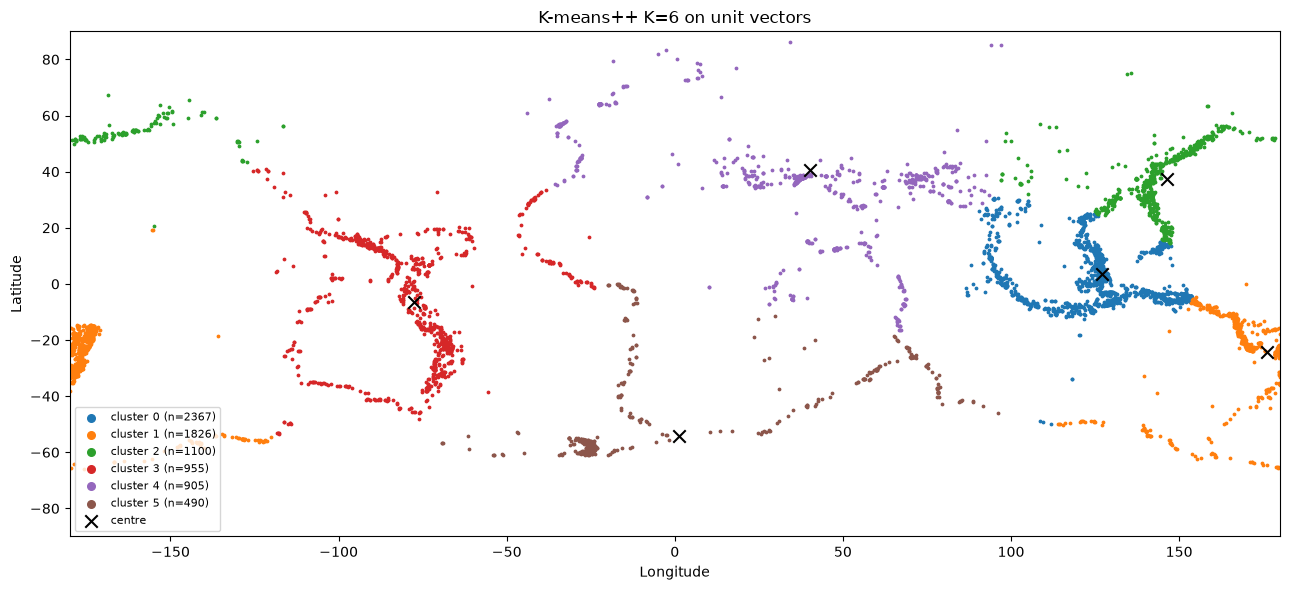

,cluster,events,% of events,centre latitude,centre longitude,median km to centre,95th percentile km to centre,median depth km,top regions
0,0,2367,30.970,3.664,126.921,1174.872,3688.002,35.000,"Philippines (793), Indonesia (760), Papua New Guinea (336)"
1,1,1826,23.891,-24.221,176.258,933.191,4419.143,11.253,"Tonga (348), Vanuatu (243), the Loyalty Islands (207)"
2,2,1100,14.392,37.346,146.283,1480.764,4385.495,13.373,"Japan region (306), Japan (279), Northern Mariana Islands (146)"
3,3,955,12.495,-6.288,-77.706,2612.789,5574.587,23.945,"Chile (160), Peru (97), Mexico (86)"
4,4,905,11.841,40.507,40.111,2833.484,5630.394,10.000,"Turkey (184), Reykjanes Ridge (86), Afghanistan (61)"
5,5,490,6.411,-54.171,1.349,1827.684,6370.120,10.000,"South Sandwich Islands region (248), southern Mid-Atlantic Ridge (48), Mid-Indian Ridg..."


In [5]:
from sc4020.generate_figures import cluster_summary, show_and_save_to

kmeans_labels = relabel_by_size(
    methods.kmeans(CHOSEN_K, n_init=10, random_state=SEED).fit_predict(U)
)
pd.DataFrame({"id": events["id"], "cluster": kmeans_labels}).to_csv(
    RESULTS / "kmeans_labels.csv", index=False
)
kmeans_summary = cluster_summary(events, kmeans_labels)
kmeans_summary.to_csv(RESULTS / "kmeans_cluster_summary.csv", index=False)

fig, ax = plt.subplots(figsize=(13, 6))
for cluster in range(CHOSEN_K):
    members = kmeans_labels == cluster
    ax.scatter(
        events.loc[members, "longitude"],
        events.loc[members, "latitude"],
        s=3,
        color=plt.cm.tab10(cluster),
        label=f"cluster {cluster} (n={members.sum()})",
    )
ax.scatter(
    kmeans_summary["centre longitude"],
    kmeans_summary["centre latitude"],
    marker="x",
    s=80,
    color="black",
    label="centre",
)
ax.set(
    xlim=(-180, 180),
    ylim=(-90, 90),
    xlabel="Longitude",
    ylabel="Latitude",
    title=f"K-means++ K={CHOSEN_K} on unit vectors",
)
legend = ax.legend(fontsize=8, loc="lower left")
for handle in legend.legend_handles[:-1]:
    handle.set_sizes([30])
plt.tight_layout()
show_and_save_to(fig, FIGURES / "kmeans_cluster_map.png")
kmeans_summary

In [6]:
k4_labels = relabel_by_size(
    methods.kmeans(4, n_init=10, random_state=SEED).fit_predict(U)
)
print(
    f"ARI between K=4 and K={CHOSEN_K}: {adjusted_rand_score(k4_labels, kmeans_labels):.3f}"
)
pd.crosstab(
    k4_labels,
    kmeans_labels,
    rownames=["K=4 cluster"],
    colnames=[f"K={CHOSEN_K} cluster"],
)

ARI between K=4 and K=6: 0.713


K=6 cluster,0,1,2,3,4,5
K=4 cluster,,,,,,
0,2357,0,1079,0,2,28
1,10,1814,1,0,0,0
2,0,12,14,955,0,372
3,0,0,6,0,903,90


**Observations**

- **K-means clusters are large regions, not belts.** The median distance from an earthquake to its cluster centre is 933 to 2,833 km, and the 95th percentile 3,688 to 6,370 km.
- The six clusters (largest first):
  - 0 (2,367, 31.0%): the Philippines, Indonesia and Papua New Guinea;
  - 1 (1,826): Tonga, Vanuatu and the Loyalty Islands. It appears at both the left and right map edges and stays one cluster, because unit vectors have no 180 degree line;
  - 2 (1,100): Japan and the Northern Mariana Islands, plus the Aleutians and Alaska at the top left;
  - 3 (955): Chile, Peru and Mexico, with the ocean lines of the eastern Pacific;
  - 4 (905): Turkey, the Reykjanes Ridge and Afghanistan. It joins the belt from the Mediterranean to Asia with the North Atlantic and western Indian Ocean lines, which are thousands of km apart;
  - 5 (490): the South Sandwich Islands and the southern Atlantic and Indian Ocean lines.
- The busiest areas get the smallest clusters in km, and the sparse ocean lines are absorbed into whichever centre is nearest.
- **K=4 vs K=6** (ARI 0.713): K=6 mostly splits K=4 clusters. K=4 cluster 0 becomes K=6 clusters 0 (2,357) and 2 (1,079); K=4 cluster 2 becomes clusters 3 (955) and 5 (372).

## 4. DBSCAN: choosing eps and min_samples

DBSCAN needs a radius `eps` (here in km on the Earth's surface) and a minimum neighbourhood size
`min_samples`. The **k-distance plot** sorts every earthquake's distance to its (min_samples - 1)-th
nearest other earthquake. A sharp knee would separate dense areas (below) from sparse ones (above) and
suggest eps. The uniform null is drawn for comparison.

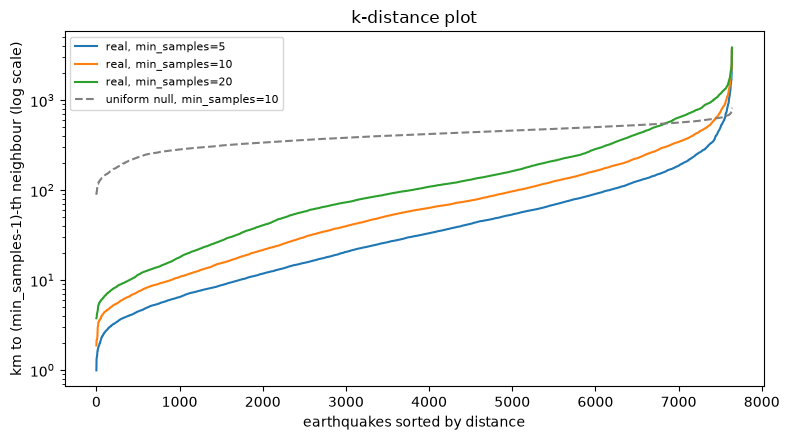

PosixPath('/Users/weiyew/Documents/SC4020/SC4020-Project-1/results/earthquakes_2023/figures/dbscan_k_distance.png')

In [7]:
from sc4020.generate_figures import show_and_save_to

MIN_SAMPLES = (5, 10, 20)
fig, ax = plt.subplots(figsize=(8, 4.5))
for m in MIN_SAMPLES:
    ax.plot(
        tuning.k_distance_curve(R, m, metric="haversine") * EARTH_RADIUS_KM,
        label=f"real, min_samples={m}",
    )
ax.plot(
    tuning.k_distance_curve(R_uniform, 10, metric="haversine") * EARTH_RADIUS_KM,
    color="grey",
    linestyle="--",
    label="uniform null, min_samples=10",
)
ax.set(
    yscale="log",
    title="k-distance plot",
    xlabel="earthquakes sorted by distance",
    ylabel="km to (min_samples-1)-th neighbour (log scale)",
)
ax.legend(fontsize=8)
plt.tight_layout()
show_and_save_to(fig, FIGURES / "dbscan_k_distance.png")

Grid: for each `min_samples`, eps is set at the 25th, 50th, 75th, 90th and 95th percentile of that k-distance curve.

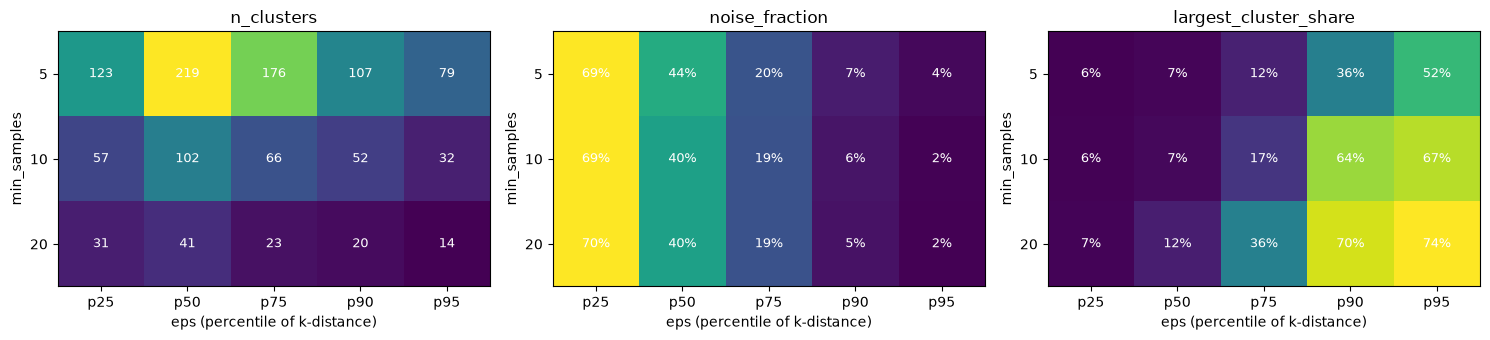

,min_samples,eps_quantile,eps_km,seconds,n_clusters,noise_fraction,largest_cluster_share,silhouette,davies_bouldin,calinski_harabasz
0,5,0.25,11.228,0.044,123,0.694,0.060,0.632,0.267,8.904e+05
1,5,0.50,30.850,0.046,219,0.436,0.068,0.646,0.306,2.501e+05
2,5,0.75,78.805,0.051,176,0.197,0.122,0.385,0.368,1.593e+04
3,5,0.90,168.030,0.056,107,0.073,0.355,0.018,0.473,7.658e+02
4,5,0.95,265.574,0.060,79,0.036,0.516,0.155,0.454,4.270e+02
5,10,0.25,20.440,0.044,57,0.694,0.065,0.878,0.187,1.332e+06
6,10,0.50,59.712,0.048,102,0.405,0.074,0.660,0.349,1.460e+05
7,10,0.75,140.491,0.054,66,0.190,0.166,0.373,0.336,8.554e+03
8,10,0.90,312.114,0.069,52,0.059,0.638,0.169,0.453,4.410e+02
9,10,0.95,455.513,0.070,32,0.025,0.667,0.242,0.536,6.231e+02


In [8]:
from sc4020.generate_figures import show_and_save_to

EPS_QUANTILES = (0.25, 0.5, 0.75, 0.9, 0.95)
rows = []
for m in MIN_SAMPLES:
    distances = tuning.k_distance_curve(R, m, metric="haversine") * EARTH_RADIUS_KM
    for q in EPS_QUANTILES:
        eps_km = float(np.quantile(distances, q))
        labels, seconds = methods.fit_predict_timed(
            methods.dbscan(eps_km / EARTH_RADIUS_KM, m, metric="haversine"), R
        )
        rows.append(
            {
                "min_samples": m,
                "eps_quantile": q,
                "eps_km": eps_km,
                "seconds": seconds,
                **evaluate(
                    R,
                    labels,
                    silhouette_sample=SILHOUETTE_SAMPLE,
                    seed=SEED,
                    metric="haversine",
                    X_davies_bouldin=U,
                ),
            }
        )
dbscan_grid = pd.DataFrame(rows)
dbscan_grid.to_csv(RESULTS / "dbscan_grid.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, (metric, fmt) in zip(
    axes,
    (
        ("n_clusters", "{:.0f}"),
        ("noise_fraction", "{:.0%}"),
        ("largest_cluster_share", "{:.0%}"),
    ),
):
    grid = dbscan_grid.pivot(index="min_samples", columns="eps_quantile", values=metric)
    ax.imshow(grid.to_numpy(), cmap="viridis", aspect="auto")
    ax.set(
        xticks=range(len(grid.columns)),
        xticklabels=[f"p{int(q * 100)}" for q in grid.columns],
        yticks=range(len(grid.index)),
        yticklabels=grid.index,
        xlabel="eps (percentile of k-distance)",
        ylabel="min_samples",
        title=metric,
    )
    for i in range(grid.shape[0]):
        for j in range(grid.shape[1]):
            ax.text(
                j,
                i,
                fmt.format(grid.iat[i, j]),
                ha="center",
                va="center",
                color="white",
                fontsize=9,
            )
plt.tight_layout()
show_and_save_to(fig, FIGURES / "dbscan_grid.png")
dbscan_grid

**Observations**

- **No knee.** The real k-distance curves rise smoothly on the log scale from about 1 to over 1,000 km. The uniform null curve is flat by comparison (about 100 to 800 km). The real curves lie below the null for most earthquakes and cross it only for the sparsest few hundred (min_samples=10) to roughly 800 (min_samples=20): density varies continuously, so there is no single distance that separates dense from sparse.
- **Every eps is a trade-off:**
  - at the 25th percentile (eps 11 to 38 km), 69% to 70% of earthquakes are noise;
  - at the 50th percentile (31 to 102 km), noise is 40% to 44% with 41 to 219 clusters;
  - at the 90th and 95th percentiles noise drops to 2% to 7%, but the largest cluster holds 36% to 74% of all earthquakes: neighbouring belts chain into one cluster.
- **Small `min_samples` fragments the belts:** `min_samples=5` gives 79 to 219 clusters.
- **Selection** (at least 2 clusters, at most 50% noise, highest silhouette): `min_samples=20`, eps 101.8 km (50th percentile): 41 clusters, 40.4% noise, largest cluster 11.8%, silhouette 0.703. That silhouette describes only the 59.6% of earthquakes that were clustered.
- Each fit takes under 0.1 s.

## 5. HDBSCAN: parameter grid

HDBSCAN removes the single global eps: it builds a hierarchy of density levels and keeps the clusters
that persist. `min_cluster_size` is scaled to about 7,600 earthquakes (25, 50, 100); `min_samples`
(how conservative the density estimate is) is the default (equal to `min_cluster_size`), 5 or 10.
Each setting is also run on the uniform null.

In [9]:
MIN_CLUSTER_SIZES = (25, 50, 100)
rows = []
for mcs in MIN_CLUSTER_SIZES:
    for ms in (None, 5, 10):
        for data_name, (Rd, Ud) in (
            ("real", (R, U)),
            ("uniform null", (R_uniform, U_uniform)),
        ):
            labels, seconds = methods.fit_predict_timed(
                methods.hdbscan(mcs, ms, metric="haversine"), Rd
            )
            scores = evaluate(
                Rd,
                labels,
                silhouette_sample=SILHOUETTE_SAMPLE,
                seed=SEED,
                metric="haversine",
                X_davies_bouldin=Ud,
            )
            sizes = (
                sorted(
                    np.bincount(labels[labels != NOISE_LABEL]).tolist(), reverse=True
                )
                if scores["n_clusters"]
                else []
            )
            rows.append(
                {
                    "data": data_name,
                    "min_cluster_size": mcs,
                    "min_samples": "default" if ms is None else ms,
                    "seconds": seconds,
                    "largest_5_sizes": sizes[:5],
                    **scores,
                }
            )
hdbscan_grid = pd.DataFrame(rows)
hdbscan_grid.to_csv(RESULTS / "hdbscan_grid.csv", index=False)
hdbscan_grid

,data,min_cluster_size,min_samples,seconds,largest_5_sizes,n_clusters,noise_fraction,largest_cluster_share,silhouette,davies_bouldin,calinski_harabasz
0,real,25,default,1.065,"[821, 554, 418, 309, 291]",47,0.227,0.107,0.657,0.351,4031.617
1,uniform null,25,default,1.105,"[1828, 181, 162, 135, 93]",20,0.590,0.239,0.338,0.542,998.229
2,real,25,5,1.023,"[576, 272, 241, 230, 207]",88,0.200,0.075,0.646,0.474,18315.047
3,uniform null,25,5,1.065,"[622, 213, 121, 109, 92]",74,0.437,0.081,0.336,0.773,2449.389
4,real,25,10,1.027,"[560, 300, 268, 257, 239]",75,0.224,0.073,0.652,0.434,19263.621
5,uniform null,25,10,1.078,"[1927, 781, 202, 164, 104]",29,0.449,0.252,0.017,0.830,382.710
6,real,50,default,1.088,"[575, 427, 391, 299, 294]",28,0.307,0.075,0.758,0.329,22962.541
7,uniform null,50,default,1.148,"[2618, 1585, 71, 62]",4,0.433,0.343,0.320,0.727,2259.334
8,real,50,5,1.025,"[576, 381, 356, 337, 332]",42,0.179,0.075,0.606,0.479,11234.341
9,uniform null,50,5,1.062,"[1063, 233, 213, 182, 153]",29,0.504,0.139,0.304,0.791,2206.967


**Observations**

- **Real data:** 15 to 88 clusters, 17.9% to 41.0% noise, largest cluster 7.3% to 10.7% of earthquakes, silhouette 0.608 to 0.757.
- **The uniform null also forms clusters** (2 to 74, with 27.5% to 51.9% noise), because HDBSCAN always finds relatively denser patches in random points. They differ from the real clusters:
  - the largest null cluster holds 8.1% to 38.6% of points, and more than 13% in 8 of 9 settings, against at most 10.7% on real data;
  - the null silhouette (0.017 to 0.598) is lower than the real one in all 9 settings.
- Real data has less noise than the null in 8 of 9 settings. The exception is `min_cluster_size=100` with default `min_samples` (41.0% vs 39.9%), where real data still has 15 clusters against 2.
- **`min_samples` of 5 or 10** lowers noise and adds clusters but lowers silhouette: at `min_cluster_size=50`, noise goes from 30.7% (default) to 17.9% and 21.4%, and silhouette from 0.757 to 0.608 and 0.627.
- **Selection** (same rule as DBSCAN): `min_cluster_size=50`, default `min_samples`: 28 clusters, 30.7% noise, largest cluster 7.5%, silhouette 0.757. Compared with the chosen DBSCAN, HDBSCAN keeps more earthquakes (69.3% vs 59.6%) with a higher silhouette (0.757 vs 0.703).
- Each fit takes about 1 s, roughly 20 times as long as DBSCAN.

## 6. What the density-based clusters contain

For each density method, the setting chosen by the rule in `../AGENTS.md`: at least 2 clusters, at most
50% noise, highest silhouette (`tuning.best_setting_by_shared_rule`). Clusters are numbered from largest to smallest.
With 28 to 41 clusters the map colours repeat; the 10 largest clusters are labelled at their centres.

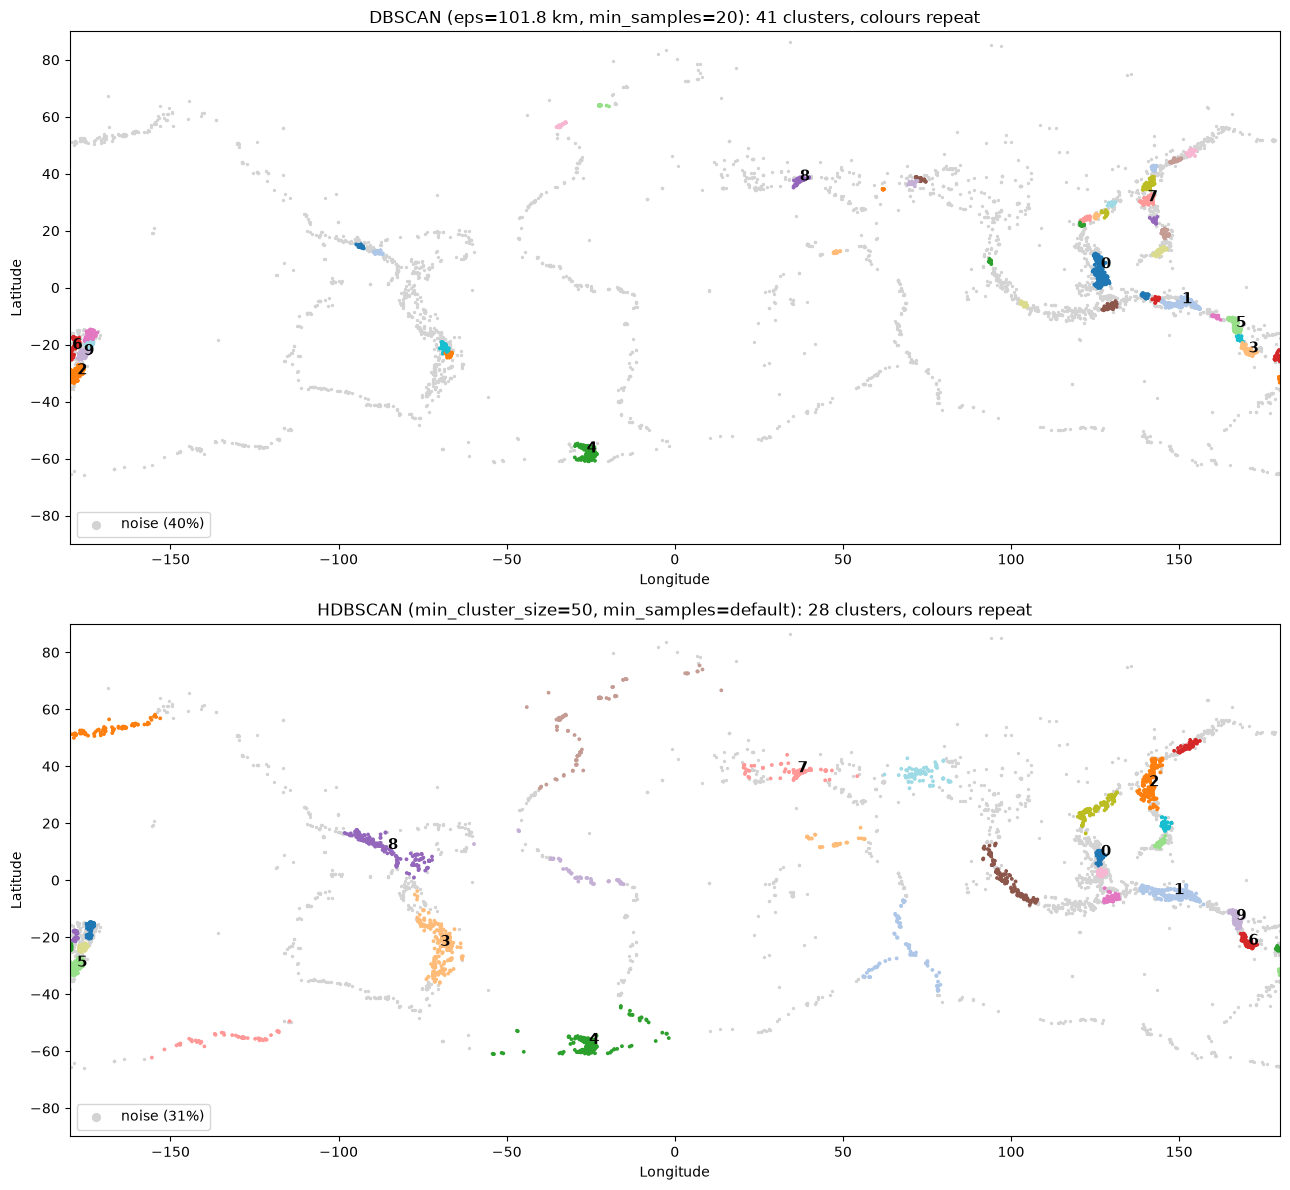

**DBSCAN: 10 largest clusters**

,cluster,events,% of events,centre latitude,centre longitude,median km to centre,95th percentile km to centre,median depth km,top regions
0,0,901,11.789,6.824,126.725,217.966,578.882,50.345,"Philippines (671), Indonesia (208), Molucca Sea (19)"
1,1,295,3.860,-5.449,150.854,274.738,600.156,40.281,"Papua New Guinea (289), Solomon Islands (6)"
2,2,292,3.820,-30.379,-177.794,148.704,308.074,18.545,"Kermadec Islands region (136), New Zealand (109), the Kermadec Islands (47)"
3,3,279,3.650,-22.737,170.632,64.150,294.206,10.000,"the Loyalty Islands (206), New Caledonia (44), Vanuatu (29)"
4,4,244,3.192,-57.841,-26.185,188.497,319.040,35.000,South Sandwich Islands region (244)
5,5,227,2.970,-13.805,166.892,149.041,368.478,33.385,"Vanuatu (174), Solomon Islands (45), Santa Cruz Islands (7)"
6,6,212,2.774,-21.539,-179.197,284.510,463.553,546.118,"the Fiji Islands (100), Fiji region (55), Fiji (43)"
7,7,210,2.748,30.380,140.589,92.423,232.493,10.000,Japan region (210)
8,8,200,2.617,37.637,37.162,78.997,207.458,10.000,"Turkey (169), Central Turkey (17), eastern Turkey (6)"
9,9,184,2.407,-23.623,-175.724,67.733,196.754,10.000,"Tonga (144), the Fiji Islands (25), Tonga region (15)"


**HDBSCAN: 10 largest clusters**

,cluster,events,% of events,centre latitude,centre longitude,median km to centre,95th percentile km to centre,median depth km,top regions
0,0,575,7.523,8.542,126.711,34.337,174.371,52.534,"Philippines (572), Philippine Islands region (3)"
1,1,427,5.587,-4.889,148.496,411.252,981.769,33.230,"Papua New Guinea (364), Indonesia (54), Solomon Islands (7)"
2,2,391,5.116,33.012,141.019,360.284,989.138,10.000,"Japan region (246), Japan (145)"
3,3,299,3.912,-23.084,-69.790,601.992,1315.825,106.733,"Chile (132), Argentina (81), Peru (66)"
4,4,294,3.847,-57.502,-25.498,212.159,1451.124,29.576,"South Sandwich Islands region (248), southern Mid-Atlantic Ridge (17), the South Sandw..."
5,5,291,3.807,-30.368,-177.787,146.484,308.938,18.266,"Kermadec Islands region (136), New Zealand (109), the Kermadec Islands (46)"
6,6,283,3.703,-22.664,170.615,71.471,294.276,10.000,"the Loyalty Islands (206), New Caledonia (44), Vanuatu (33)"
7,7,246,3.219,37.914,36.506,129.532,1190.655,10.000,"Turkey (184), Central Turkey (17), Greece (12)"
8,8,234,3.062,10.927,-85.339,778.062,1432.633,35.000,"Mexico (51), Colombia (49), Panama (35)"
9,9,227,2.970,-13.951,166.978,135.882,350.680,33.385,"Vanuatu (180), Solomon Islands (40), Santa Cruz Islands (7)"


In [10]:
from sc4020.generate_figures import cluster_summary, show_and_save_to

MAX_NOISE = 0.5
# tab20 without its two greys (indices 14 and 15), so no cluster is drawn in the same colour as noise
PALETTE = [
    colour for index, colour in enumerate(plt.cm.tab20.colors) if index not in (14, 15)
]
best_dbscan = tuning.best_setting_by_shared_rule(dbscan_grid, MAX_NOISE)
best_hdbscan = tuning.best_setting_by_shared_rule(hdbscan_grid, MAX_NOISE)
HDBSCAN_MIN_SAMPLES = (
    None
    if best_hdbscan["min_samples"] == "default"
    else int(best_hdbscan["min_samples"])
)
density_models = {
    "DBSCAN": (
        lambda: methods.dbscan(
            best_dbscan["eps_km"] / EARTH_RADIUS_KM,
            int(best_dbscan["min_samples"]),
            metric="haversine",
        ),
        f"eps={best_dbscan['eps_km']:.1f} km, min_samples={int(best_dbscan['min_samples'])}",
    ),
    "HDBSCAN": (
        lambda: methods.hdbscan(
            int(best_hdbscan["min_cluster_size"]),
            HDBSCAN_MIN_SAMPLES,
            metric="haversine",
        ),
        f"min_cluster_size={int(best_hdbscan['min_cluster_size'])}, min_samples={best_hdbscan['min_samples']}",
    ),
}
density_labels = {
    name: relabel_by_size(make().fit_predict(R))
    for name, (make, _) in density_models.items()
}
density_summaries = {
    name: cluster_summary(events, labels) for name, labels in density_labels.items()
}
for name, labels in density_labels.items():
    pd.DataFrame({"id": events["id"], "cluster": labels}).to_csv(
        RESULTS / f"{name.lower()}_labels.csv", index=False
    )
    density_summaries[name].to_csv(
        RESULTS / f"{name.lower()}_cluster_summary.csv", index=False
    )

fig, axes = plt.subplots(2, 1, figsize=(13, 12))
for ax, (name, labels) in zip(axes, density_labels.items()):
    noise = labels == NOISE_LABEL
    ax.scatter(
        events.loc[noise, "longitude"],
        events.loc[noise, "latitude"],
        s=2,
        color="lightgrey",
        label=f"noise ({noise.mean():.0%})",
    )
    ax.scatter(
        events.loc[~noise, "longitude"],
        events.loc[~noise, "latitude"],
        s=3,
        color=[PALETTE[label % len(PALETTE)] for label in labels[~noise]],
    )
    for _, row in density_summaries[name].head(10).iterrows():
        ax.annotate(
            str(int(row["cluster"])),
            (row["centre longitude"], row["centre latitude"]),
            fontsize=11,
            weight="bold",
        )
    ax.set(
        xlim=(-180, 180),
        ylim=(-90, 90),
        xlabel="Longitude",
        ylabel="Latitude",
        title=f"{name} ({density_models[name][1]}): {labels.max() + 1} clusters, colours repeat",
    )
    ax.legend(markerscale=4, loc="lower left")
plt.tight_layout()
show_and_save_to(fig, FIGURES / "density_cluster_maps.png")

for name, summary in density_summaries.items():
    display(Markdown(f"**{name}: 10 largest clusters**"))
    display(summary.head(10))

### Which earthquakes become noise?

Noise should be the isolated earthquakes. The distance to the nearest other earthquake (EDA section 6)
is compared for noise and clustered earthquakes, and the share of each region's earthquakes that is
clustered is compared between the two methods (regions with at least 100 earthquakes).

In [11]:
nearest = nearest_neighbour_km(events["latitude"], events["longitude"])
display(
    pd.DataFrame(
        {
            name: {
                "noise earthquakes": int((labels == NOISE_LABEL).sum()),
                "median km to nearest earthquake, noise": float(
                    np.median(nearest[labels == NOISE_LABEL])
                ),
                "median km to nearest earthquake, clustered": float(
                    np.median(nearest[labels != NOISE_LABEL])
                ),
            }
            for name, labels in density_labels.items()
        }
    )
)

regions = region_from_place(events["place"])
by_region = pd.DataFrame({"earthquakes": regions.value_counts()})
for name, labels in density_labels.items():
    by_region[f"{name} clustered %"] = (
        100
        * pd.Series(labels != NOISE_LABEL, index=events.index).groupby(regions).mean()
    )
by_region = by_region[by_region["earthquakes"] >= 100]
by_region["HDBSCAN minus DBSCAN"] = (
    by_region["HDBSCAN clustered %"] - by_region["DBSCAN clustered %"]
)
by_region.sort_values("HDBSCAN minus DBSCAN", ascending=False)

,DBSCAN,HDBSCAN
noise earthquakes,3084.000,2347.000
"median km to nearest earthquake, noise",23.816,20.009
"median km to nearest earthquake, clustered",6.280,7.254


,earthquakes,DBSCAN clustered %,HDBSCAN clustered %,HDBSCAN minus DBSCAN
place,,,,
Alaska,120,0.000,74.167,74.167
Chile,160,37.500,82.500,45.000
Japan,309,63.754,81.230,17.476
Papua New Guinea,378,86.243,96.296,10.053
Indonesia,760,45.658,54.211,8.553
Turkey,184,91.848,100.000,8.152
South Sandwich Islands region,248,98.387,100.000,1.613
Northern Mariana Islands,160,81.875,82.500,0.625
Kermadec Islands region,140,97.143,97.143,0.000


**Observations**

- **DBSCAN keeps compact patches only.** Its clusters are dense spots, mostly in the western Pacific, Turkey and the South Sandwich Islands. Alaska, most of the Americas and nearly all of the ocean lines are noise. Its largest cluster (901 earthquakes) joins the Philippines (671) and Indonesia (208).
- **HDBSCAN also keeps long, sparser belt segments:** Alaska and the Aleutians, Chile, Argentina and Peru (cluster 3, median 602 km to centre), Mexico to Panama (cluster 8, median 778 km), and segments of the ocean lines in the Atlantic, Indian and southern Pacific oceans. Its largest cluster is the Philippines alone (575 earthquakes, median 34 km to centre).
- **Aftershock sequences form their own clusters** in both methods: Turkey (DBSCAN cluster 8, 200 earthquakes; HDBSCAN cluster 7, 246) and the Philippines (EDA section 9).
- **Noise is sparser than clustered earthquakes but not isolated.** The median distance to the nearest other earthquake is 23.8 km (DBSCAN noise) and 20.0 km (HDBSCAN noise), against 6.3 and 7.3 km for clustered earthquakes. The most isolated earthquakes in the EDA were over 800 km from any other, so noise includes whole sparse belts, not only isolated events.
- **HDBSCAN clusters more of the sparse belts:** Alaska goes from 0% clustered (DBSCAN) to 74.2%, Chile from 37.5% to 82.5%, and Japan from 63.8% to 81.2%.
- **But less of some dense areas:** the Solomon Islands go from 70.3% to 39.8%, the Fiji Islands from 84.5% to 58.8%, Tonga from 94.8% to 69.5% and the Philippines from 84.6% to 75.2%. HDBSCAN extracts each cluster at its own density level, so earthquakes around a very dense core can fall below that level and become noise, even though a fixed 102 km radius includes them.

## 7. Gaussian Mixture Models (GMM)

GMM models the data as a mixture of Gaussian distributions on the 3D unit vectors. Model selection sweeps
K from 2 to 12 across the four covariance types (full, tied, diag, spherical) to find the lowest BIC
(`tuning.select_gmm_by_bic`). The score table is saved to `gmm_selection.csv`.


In [12]:
gmm_sel = tuning.select_gmm_by_bic(U, k_range=range(2, 13), random_state=SEED)
gmm_tried = pd.DataFrame(gmm_sel.tried)
gmm_tried["bic"] = -gmm_tried["score"]
gmm_tried.to_csv(RESULTS / "gmm_selection.csv", index=False)

print(f"GMM chosen params: {gmm_sel.params}, lowest BIC: {gmm_tried['bic'].min():.2f}")
gmm_summary_table = gmm_tried.pivot(
    index="n_components", columns="covariance_type", values="bic"
)
display(gmm_summary_table)

# Fit chosen GMM model and record labels
gmm_model = methods.gmm(
    gmm_sel.params["n_components"],
    covariance_type=gmm_sel.params["covariance_type"],
    random_state=SEED,
)
gmm_labels = relabel_by_size(gmm_model.fit_predict(U))

GMM chosen params: {'n_components': 12, 'covariance_type': 'full'}, lowest BIC: -31790.35


covariance_type,diag,full,spherical,tied
n_components,,,,
2,25703.585,17103.124,27450.702,25036.019
3,12297.174,3358.272,16487.371,22133.042
4,10773.976,-1881.709,14680.137,18212.966
5,7395.543,-7770.938,10633.781,17084.968
6,4437.446,-9504.627,7657.566,14634.834
7,-2207.790,-10957.620,3681.133,13745.560
8,-4577.748,-16105.302,4682.344,13080.066
9,-7559.874,-21496.578,-1098.153,10857.005
10,-12354.557,-23226.706,-1821.214,9459.097


**Observations**

- **Lowest BIC occurs at K=12 with full covariance** (BIC -31,790.35; K=11 is -29,002.69). Across all covariance types, full covariance achieves significantly lower BIC than diagonal, tied or spherical.
- **BIC is still falling at K=12**, the upper edge of the tested range [2, 12]. With 7,643 earthquakes distributed along dozens of plate boundaries, additional Gaussian components continue to capture local density variations along belts without severe penalty.


## 8. Spectral clustering

Spectral clustering partitions the 10-nearest-neighbour graph (`affinity="nearest_neighbors"`) built on the
3D unit vectors using the K-means cluster count (K=6). Scikit-learn issues a warning if the nearest-neighbour
graph is disconnected.


In [13]:
from scipy.sparse.csgraph import connected_components
from sklearn.neighbors import kneighbors_graph

adj = kneighbors_graph(U, n_neighbors=10, mode="connectivity", include_self=True)
adj_sym = 0.5 * (adj + adj.T)
n_graph_components, _ = connected_components(adj_sym)
print(f"10-NN graph symmetric connected components: {n_graph_components}")

with warnings.catch_warnings(record=True) as spectral_warnings:
    warnings.simplefilter("always")
    spec_model = methods.spectral(
        CHOSEN_K, affinity="nearest_neighbors", random_state=SEED
    )
    spec_labels, spec_seconds = methods.fit_predict_timed(spec_model, U)
    spec_labels = relabel_by_size(spec_labels)

print(
    f"Spectral fit time: {spec_seconds:.3f} s; warnings caught: {len(spectral_warnings)}"
)
for w in spectral_warnings:
    print("warning:", w.message)

10-NN graph symmetric connected components: 1
Spectral fit time: 0.092 s; warnings caught: 0


**Observations**

- **Graph connectivity:** The symmetric 10-nearest-neighbour graph on all 7,643 earthquakes forms a single connected component (1 connected component). No disconnection warnings are issued by scikit-learn.
- **Runtime:** Fitting Spectral clustering on 7,643 points takes 0.09 s.


## 9. Method comparison

One setting per method:
- **K-means++**: K=6, one start (`n_init=1`), seed 0.
- **DBSCAN** and **HDBSCAN**: the settings chosen by the shared density rule from section 6.
- **GMM**: lowest BIC model (K=12, full covariance).
- **Spectral**: K=6, 10-nearest-neighbour graph on unit vectors.

Each run is repeated on its null (shuffled null on unit vectors for partitioning/model methods; uniform null for density methods). Metrics match the standard project columns, including DBCV (3,000-sample estimate).


In [14]:
from sc4020.metrics import dbcv_score

DBCV_SAMPLE = 3000
gmm_k = gmm_sel.params["n_components"]
gmm_cov = gmm_sel.params["covariance_type"]

settings = {
    "K-means++": (
        lambda: methods.kmeans(CHOSEN_K, n_init=1, random_state=SEED),
        f"K={CHOSEN_K}, n_init=1",
    ),
    **density_models,
    "GMM": (
        lambda: methods.gmm(gmm_k, covariance_type=gmm_cov, random_state=SEED),
        f"n_components={gmm_k}, covariance_type={gmm_cov}",
    ),
    "Spectral": (
        lambda: methods.spectral(
            CHOSEN_K, affinity="nearest_neighbors", random_state=SEED
        ),
        f"K={CHOSEN_K}, affinity=nearest_neighbors",
    ),
}

rows, comparison_labels = [], {}
for name, (make, setting) in settings.items():
    uses_unit_vectors = name in ("K-means++", "GMM", "Spectral")
    labels, seconds = methods.fit_predict_timed(make(), U if uses_unit_vectors else R)
    null_R, null_U = shuffled[0] if uses_unit_vectors else (R_uniform, U_uniform)
    null_scores = evaluate(
        null_R,
        make().fit_predict(null_U if uses_unit_vectors else null_R),
        silhouette_sample=SILHOUETTE_SAMPLE,
        seed=SEED,
        metric="haversine",
        X_davies_bouldin=null_U,
    )
    comparison_labels[name] = labels
    scores = evaluate(
        R,
        labels,
        silhouette_sample=SILHOUETTE_SAMPLE,
        seed=SEED,
        metric="haversine",
        X_davies_bouldin=U,
    )
    dbcv = dbcv_score(U, labels, sample_size=DBCV_SAMPLE, random_state=SEED)
    rows.append(
        {
            "method": name,
            "params": setting,
            "n_clusters": scores["n_clusters"],
            "noise_fraction": scores["noise_fraction"],
            "silhouette": scores["silhouette"],
            "davies_bouldin": scores["davies_bouldin"],
            "dbcv": dbcv,
            "ari": np.nan,
            "nmi": np.nan,
            "fit_seconds": seconds,
            "largest_cluster_share": scores["largest_cluster_share"],
            "null_silhouette": null_scores["silhouette"],
        }
    )

comparison = pd.DataFrame(rows)
comparison.to_csv(RESULTS / "method_comparison.csv", index=False)

agreement = pd.DataFrame(
    {
        a: {
            b: adjusted_rand_score(comparison_labels[a], comparison_labels[b])
            for b in comparison_labels
        }
        for a in comparison_labels
    }
)
agreement.to_csv(RESULTS / "method_agreement.csv")
display(comparison)
display(Markdown("**Agreement (ARI)**"))
agreement

,method,params,n_clusters,noise_fraction,silhouette,davies_bouldin,dbcv,ari,nmi,fit_seconds,largest_cluster_share,null_silhouette
0,K-means++,"K=6, n_init=1",6,0.000,0.529,0.738,-0.819,NaN,NaN,0.006,0.310,0.390
1,DBSCAN,"eps=101.8 km, min_samples=20",41,0.404,0.703,0.351,0.378,NaN,NaN,0.052,0.118,NaN
2,HDBSCAN,"min_cluster_size=50, min_samples=default",28,0.307,0.758,0.329,0.464,NaN,NaN,1.089,0.075,0.320
3,GMM,"n_components=12, covariance_type=full",12,0.000,0.442,0.907,-0.603,NaN,NaN,0.406,0.167,0.352
4,Spectral,"K=6, affinity=nearest_neighbors",6,0.000,0.333,0.914,-0.816,NaN,NaN,0.089,0.316,0.320


**Agreement (ARI)**

,K-means++,DBSCAN,HDBSCAN,GMM,Spectral
K-means++,1.000,0.104,0.135,0.482,0.695
DBSCAN,0.104,1.000,0.416,0.179,0.137
HDBSCAN,0.135,0.416,1.000,0.209,0.125
GMM,0.482,0.179,0.209,1.000,0.450
Spectral,0.695,0.137,0.125,0.450,1.000


### Belt check: do methods cut belts or merge them?

For each method, we measure how many clusters the 10 largest HDBSCAN belts fall into, and how many connected pieces
each cluster forms in the 10-nearest-neighbour graph (multiple pieces indicate that distant, disconnected belts are joined).


In [15]:
hdbscan_labels = density_labels["HDBSCAN"]
hdbscan_top = density_summaries["HDBSCAN"].set_index("cluster")


# Connected pieces in the symmetric 10-NN graph for each cluster
def cluster_connected_pieces(labels):
    pieces = {}
    for c in np.unique(labels):
        if c == NOISE_LABEL:
            continue
        members = np.where(labels == c)[0]
        subgraph = adj_sym[members, :][:, members]
        n_comp, _ = connected_components(subgraph)
        pieces[c] = n_comp
    return pieces


belt_rows = []
for cluster in range(10):
    members = hdbscan_labels == cluster
    row = {
        "HDBSCAN cluster": cluster,
        "earthquakes": int(members.sum()),
        "top regions": hdbscan_top.loc[cluster, "top regions"],
    }
    for method_name in ["K-means++", "GMM", "Spectral"]:
        counts = pd.Series(comparison_labels[method_name][members]).value_counts()
        row[f"{method_name} clusters"] = len(counts)
        row[f"{method_name} main %"] = 100 * counts.iloc[0] / members.sum()
    belt_rows.append(row)
display(pd.DataFrame(belt_rows))

# Connected pieces summary per method
pieces_summary = []
for method_name in ["K-means++", "GMM", "Spectral"]:
    pieces = cluster_connected_pieces(comparison_labels[method_name])
    pieces_summary.append(
        {
            "method": method_name,
            "n_clusters": len(pieces),
            "clusters with >1 piece": sum(p > 1 for p in pieces.values()),
            "max pieces in one cluster": max(pieces.values()),
            "mean pieces per cluster": float(np.mean(list(pieces.values()))),
        }
    )
display(pd.DataFrame(pieces_summary))

,HDBSCAN cluster,earthquakes,top regions,K-means++ clusters,K-means++ main %,GMM clusters,GMM main %,Spectral clusters,Spectral main %
0,0,575,"Philippines (572), Philippine Islands region (3)",1,100.000,1,100.000,1,100.000
1,1,427,"Papua New Guinea (364), Indonesia (54), Solomon Islands (7)",2,88.759,1,100.000,1,100.000
2,2,391,"Japan region (246), Japan (145)",1,100.000,2,66.496,2,62.148
3,3,299,"Chile (132), Argentina (81), Peru (66)",1,100.000,1,100.000,2,96.656
4,4,294,"South Sandwich Islands region (248), southern Mid-Atlantic Ridge (17), the South Sandw...",1,100.000,2,87.755,1,100.000
5,5,291,"Kermadec Islands region (136), New Zealand (109), the Kermadec Islands (46)",1,100.000,1,100.000,1,100.000
6,6,283,"the Loyalty Islands (206), New Caledonia (44), Vanuatu (33)",1,100.000,1,100.000,1,100.000
7,7,246,"Turkey (184), Central Turkey (17), Greece (12)",1,100.000,1,100.000,1,100.000
8,8,234,"Mexico (51), Colombia (49), Panama (35)",1,100.000,1,100.000,1,100.000
9,9,227,"Vanuatu (180), Solomon Islands (40), Santa Cruz Islands (7)",1,100.000,1,100.000,1,100.000


,method,n_clusters,clusters with >1 piece,max pieces in one cluster,mean pieces per cluster
0,K-means++,6,4,4,2.333
1,GMM,12,5,10,2.167
2,Spectral,6,0,1,1.000


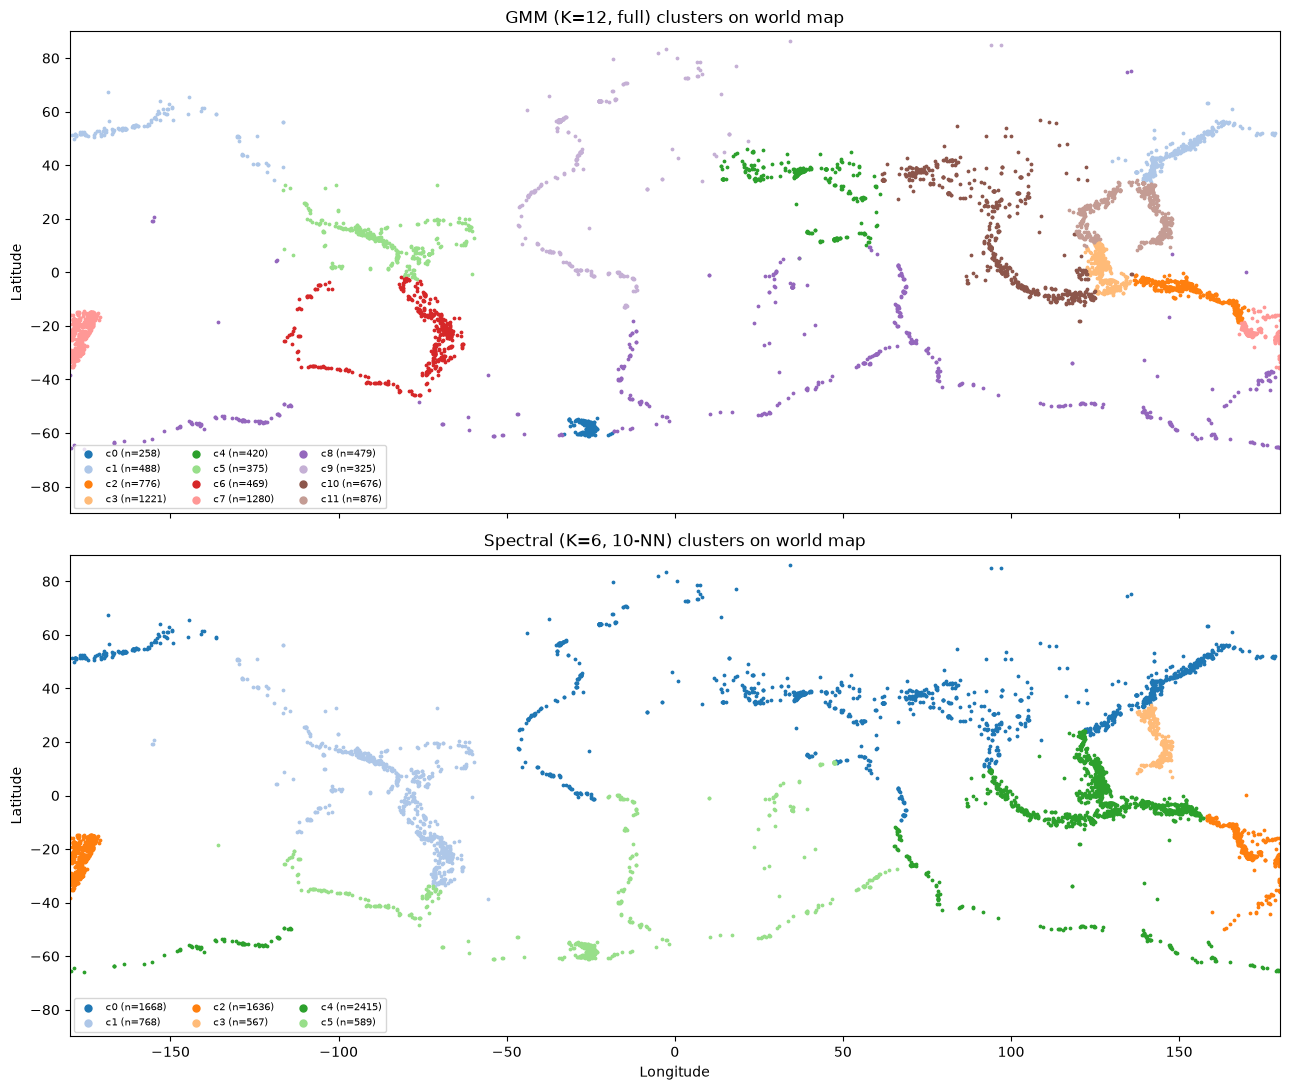

PosixPath('/Users/weiyew/Documents/SC4020/SC4020-Project-1/results/earthquakes_2023/figures/gmm_spectral_clusters.png')

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(13, 11), sharex=True, sharey=True)
for ax, (m_name, m_labels) in zip(
    axes,
    [
        ("GMM (K=12, full)", comparison_labels["GMM"]),
        ("Spectral (K=6, 10-NN)", comparison_labels["Spectral"]),
    ],
):
    n_c = len(np.unique(m_labels))
    for c in range(n_c):
        members = m_labels == c
        ax.scatter(
            events.loc[members, "longitude"],
            events.loc[members, "latitude"],
            s=3,
            color=plt.cm.tab20(c % 20),
            label=f"c{c} (n={members.sum()})",
        )
    ax.set(
        xlim=(-180, 180),
        ylim=(-90, 90),
        ylabel="Latitude",
        title=f"{m_name} clusters on world map",
    )
    leg = ax.legend(fontsize=7, loc="lower left", ncol=3)
    for handle in leg.legend_handles:
        handle.set_sizes([25])
axes[1].set(xlabel="Longitude")
plt.tight_layout()
show_and_save_to(fig, FIGURES / "gmm_spectral_clusters.png")

**Observations**

- **GMM (K=12, full covariance):** achieves silhouette 0.442 (null 0.352), Davies-Bouldin 0.907, and DBCV -0.603. GMM has no noise class, so every earthquake joins a component, and components bridge distant belts: 5 of the 12 clusters have more than 1 connected piece in the 10-NN graph, with one cluster spanning up to 10 disconnected pieces.
- **Spectral clustering (K=6, 10-NN graph):** achieves silhouette 0.333 (null 0.320), Davies-Bouldin 0.914, and DBCV -0.816. Unlike K-means and GMM, **every Spectral cluster forms exactly 1 connected component in the 10-NN graph** (0 clusters with >1 piece, mean 1.000). Its clusters follow chains of neighbouring earthquakes and never join belts that the graph leaves unconnected. Its silhouette, however, is only 0.013 above the shuffled null: the label-free score rates the one method that never joins distant belts as close to no structure. However, because K is constrained to 6 while the Earth has dozens of plate boundaries, Spectral merges adjacent belts along graph paths (its largest cluster holds 31.6% of earthquakes).
- **Agreement:** Spectral agrees strongly with K-means++ (ARI 0.695). GMM agrees moderately with K-means++ (0.482) and Spectral (0.450). Agreement between the methods without noise and HDBSCAN remains low (ARI 0.13 to 0.21) because HDBSCAN marks 30.7% of points as noise, whereas partitioning methods force every isolated earthquake into a cluster.
- **DBCV:** HDBSCAN scores highest on DBCV (0.464), followed by DBSCAN (0.378), as expected for a score built for density clusters. In contrast, K-means++ (-0.819), GMM (-0.603), and Spectral (-0.816) all score negative DBCV because their cluster boundaries pass through dense data without density voids.


## 10. Summary

| Question | Answer from this notebook |
|---|---|
| Is there cluster structure? | Yes. K-means silhouette is about 0.14 above the shuffled null from K=4; DBSCAN finds no clusters on the uniform null; HDBSCAN produces 28 clusters with higher silhouette than the null |
| What K? | K=6 for K-means and Spectral (seed ARI 0.993, Davies-Bouldin 0.738); K=12 for GMM by BIC |
| What do K-means clusters mean? | Large spherical regions that each merge several distant belts (e.g. Turkey with Reykjanes Ridge) |
| GMM | Lowest BIC at K=12 (full covariance; BIC still falling). Captures ellipsoidal shapes along belts, but joins sparse points across belts |
| Spectral | K=6 on 10-NN graph: 0 disconnected graph warnings. Every cluster is 1 connected graph component, but K=6 forces adjacent belts to merge |
| DBSCAN | eps 101.8 km, `min_samples=20`: 41 compact clusters, 40.4% noise. No knee in the k-distance curve |
| HDBSCAN | `min_cluster_size=50`, default `min_samples`: 28 clusters, 30.7% noise, silhouette 0.758, DBCV 0.464. Follows long belts of varying density |
| Agreement | Methods without noise vs HDBSCAN ARI 0.13 to 0.21, vs DBSCAN 0.10 to 0.18; HDBSCAN separates noise (30.7%), whereas partitioning methods partition the whole sphere |
| Runtime | K-means < 0.01 s, Spectral ~0.09 s, DBSCAN ~0.05 s, GMM ~0.42 s, HDBSCAN ~1.1 s |
